# k-means from Scratch

## Learning Objectives
- Understand clustering as geometry
- Implement k-means without sklearn
- See the effect of initialization
- Understand representation space importance

In [63]:
import numpy as np
import matplotlib.pyplot as plt

In [64]:
np.random.seed(0)

X1 = np.random.randn(100, 2) + np.array([2, 2])
X2 = np.random.randn(100, 2) + np.array([-2, -2])
X = np.vstack([X1, X2])

Text(0.5, 1.0, 'Unlabeled Data')

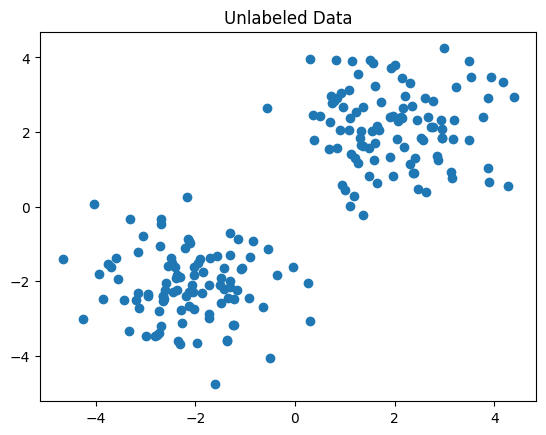

In [65]:
plt.scatter(X[:,0], X[:,1])
plt.title("Unlabeled Data")

## k-means Objective

$$
\min_{\{\mu_k\}} \sum_{i=1}^N \|x_i - \mu_{c_i}\|^2
$$

This is a **purely geometric objective**.

In [66]:
def init_centroids(X, k):
    indices = np.random.choice(len(X), k, replace=False)
    return X[indices]

In [67]:
def assign_clusters(X, centroids):
    distances = np.linalg.norm(X[:, None] - centroids[None, :], axis=2)
    return np.argmin(distances, axis=1)

In [68]:
def update_centroids(X, labels, k):
    return np.array([X[labels == i].mean(axis=0) for i in range(k)])

In [69]:
def kmeans(X, k, max_iters=100):
    centroids = init_centroids(X, k)
    
    for _ in range(max_iters):
        labels = assign_clusters(X, centroids)
        new_centroids = update_centroids(X, labels, k)
        
        if np.allclose(centroids, new_centroids):
            break
        centroids = new_centroids
    
    return labels, centroids

Text(0.5, 1.0, 'k-means Result')

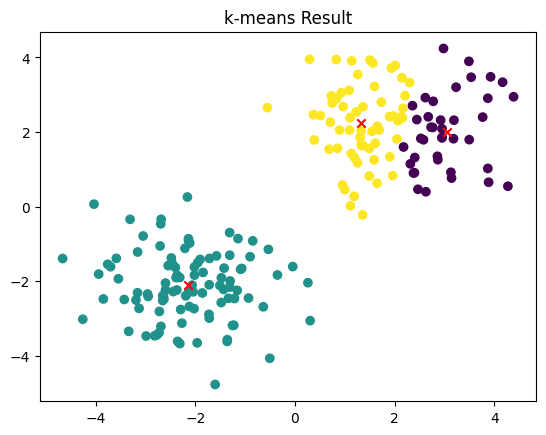

In [70]:
labels, centroids = kmeans(X, k=3)

plt.scatter(X[:,0], X[:,1], c=labels)
plt.scatter(centroids[:,0], centroids[:,1], c='red', marker='x')
plt.title("k-means Result")

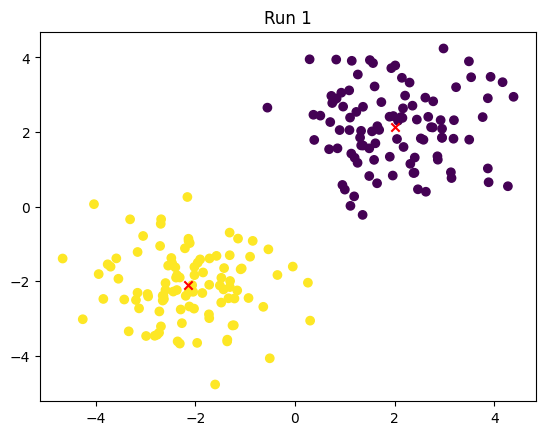

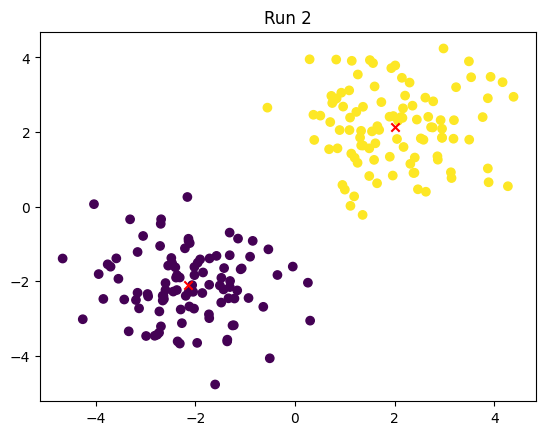

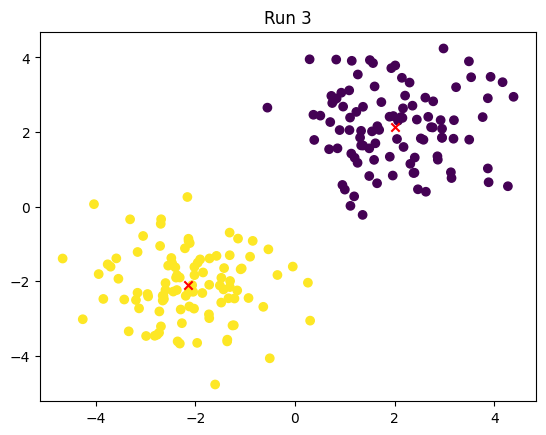

In [71]:
for i in range(3):
    labels, centroids = kmeans(X, k=2)
    plt.scatter(X[:,0], X[:,1], c=labels)
    plt.scatter(centroids[:,0], centroids[:,1], c='red', marker='x')
    plt.title(f"Run {i+1}")
    plt.show()

In [72]:
class KMeans:
    """
    k-means clustering implemented from scratch.

    Objective:
    Minimize the sum of squared distances between
    samples and their assigned cluster centroids.
    """

    def __init__(self, n_clusters, max_iters=100):
        self.k = n_clusters
        self.max_iters = max_iters
        self.centroids = None # parameter


    def fit(self, X):
        """
        Perform k-means clustering.

        Parameters
        ----------
        X : array of shape (N, D)
            Input data
        """
        N, D = X.shape


        # Step 1: initialize controids: Randomly select k different samples as initial centroids
        # tips: Different initializations may lead to different local optima.
        indices = np.random.choice(N, self.k, replace=False)
        self.centroids = X[indices]

        # Step 2: Main optimization loop
        for _ in range(self.max_iters):
            # Create empty clusters
            clusters = [[] for _ in range(self.k)]
            
            for i in range(N):
                # Compute distance from sample to each centroid
                distances = np.linalg.norm(X[i] - self.centroids, axis=1)
                
                # Assign sample to the nearest centroid
                cluster_idx = np.argmin(distances)
                clusters[cluster_idx].append(i)

            new_centroids = np.zeros_like(self.centroids)
            
            for k in range(self.k):
                if clusters[k]:
                    # Update centroid as the mean of assigned samples
                    # The mean is not arbitrary — it is the minimizer of squared Euclidean distance.
                    new_centroids[k] = np.mean(X[clusters[k]], axis=0)
                else:
                    # Handle empty cluster by reinitializing randomly
                    new_centroids[k] = X[np.random.choice(N)]

            # If centroids do not change, the algorithm has converged
            if np.allclose(self.centroids, new_centroids):
                break
            
            self.centroids = new_centroids


    def predict(self, X):
        """
        Assign each sample to the nearest centroid.

        Parameters
        ----------
        X : array of shape (N, D)

        Returns
        -------
        labels : array of shape (N,)
        """
        labels = []
        
        for x in X:
            distances = np.linalg.norm(x - self.centroids, axis=1)
            labels.append(np.argmin(distances))
        
        return np.array(labels)

In [73]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Cluster 1 centered at (2, 2)
X1 = np.random.randn(50, 2) + np.array([2, 2])

# Cluster 2 centered at (-2, -2)
X2 = np.random.randn(50, 2) + np.array([-2, -2])



In [76]:
# Combine
X_kmeans = np.vstack([X1, X2])

kmeans = KMeans(n_clusters=3, max_iters=100)
kmeans.fit(X_kmeans)
labels = kmeans.predict(X_kmeans)
centroids = kmeans.centroids

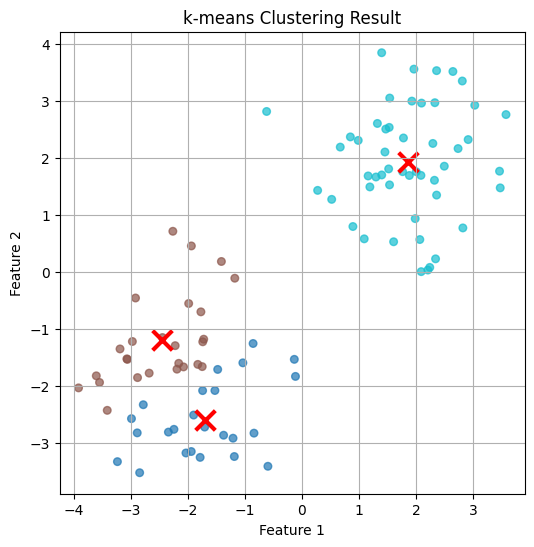

In [77]:
plt.figure(figsize=(6, 6))

# Plot data points, colored by cluster label
plt.scatter(
    X_kmeans[:, 0],
    X_kmeans[:, 1],
    c=labels,
    cmap="tab10",
    s=30,
    alpha=0.7
)

# Plot centroids
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    c="red",
    marker="x",
    s=200,
    linewidths=3,
    label="Centroids"
)

plt.title("k-means Clustering Result")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
# plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()

## Key Takeaways

- k-means alternates between assignment and update
- Objective always decreases, but only to local minima
- Initialization matters
- k-means is only as good as the feature space